# Real gases with cubic equations of state

This notebook covers five topics with `realgas`:

1. CO2 isotherms and the van der Waals loop,
2. the compressibility chart Z(P) at several temperatures, comparing four equations of state,
3. vapour-pressure curves compared with the acentric-factor rule,
4. the phase envelope (saturated liquid and vapour densities),
5. residual enthalpy: how much a real gas departs from ideal.

Units are SI throughout.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import realgas as rg

co2 = rg.get("CO2")
pr = rg.PengRobinson(co2)

## 1. CO2 isotherms (Peng-Robinson)

Below $T_c$ the cubic has a loop. The dashed lines mark the saturation pressure, where liquid and vapour fugacities are equal.

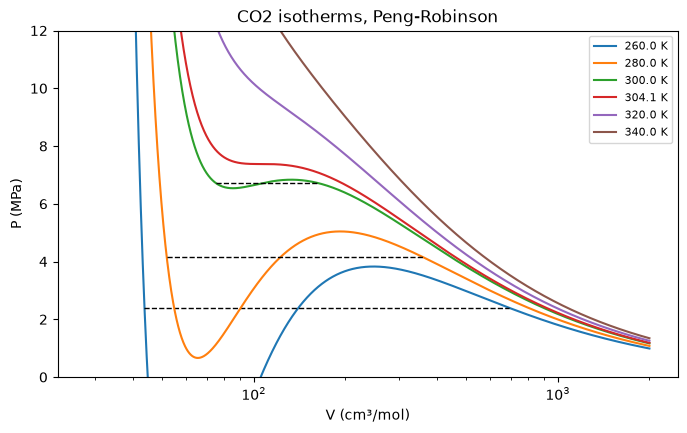

In [2]:
V = np.geomspace(1.05 * pr.b, 2e-3, 2000)
plt.figure(figsize=(8, 4.5))
for T in (260, 280, 300, co2.Tc, 320, 340):
    plt.plot(V * 1e6, pr.pressure(T, V) / 1e6, label=f"{T:.1f} K")
    if T < co2.Tc:
        Ps = pr.saturation_pressure(T)
        plt.hlines(Ps / 1e6, pr.volume(T, Ps, "liquid") * 1e6, pr.volume(T, Ps, "vapor") * 1e6, colors="k", linestyles="--", lw=1)
plt.xscale("log"); plt.ylim(0, 12); plt.xlabel("V (cm³/mol)"); plt.ylabel("P (MPa)"); plt.legend(fontsize=8)
plt.title("CO2 isotherms, Peng-Robinson"); plt.show()

## 2. Compressibility of methane: four equations of state

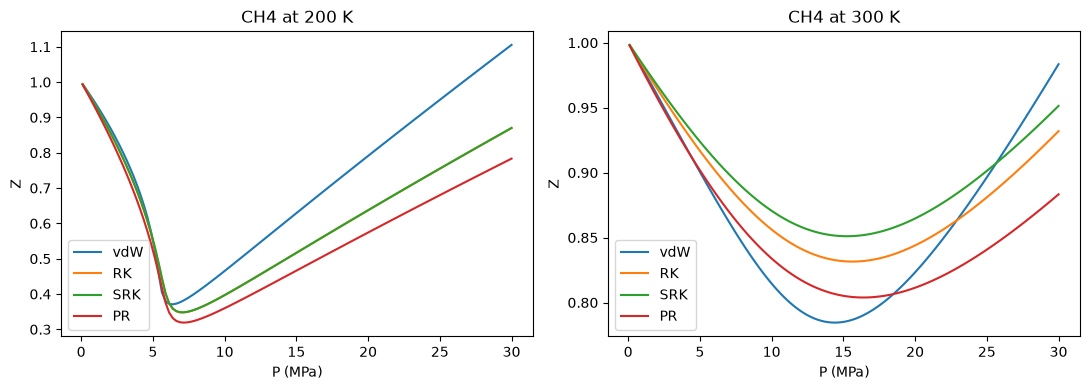

In [3]:
ch4 = rg.get("CH4")
P = np.linspace(1e5, 3e7, 120)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, T in zip(axes, (200.0, 300.0)):
    for name, E in rg.EOS.items():
        e = E(ch4)
        ax.plot(P / 1e6, [e.Z(T, p) for p in P], label=name)
    ax.set_title(f"CH4 at {T:.0f} K"); ax.set_xlabel("P (MPa)"); ax.set_ylabel("Z"); ax.legend()
plt.tight_layout(); plt.show()

## 3. Vapour pressure and the acentric factor

By definition, $\omega = -1 - \log_{10}(P_{sat}/P_c)$ at $T_r = 0.7$. Each curve should pass through the marked point.

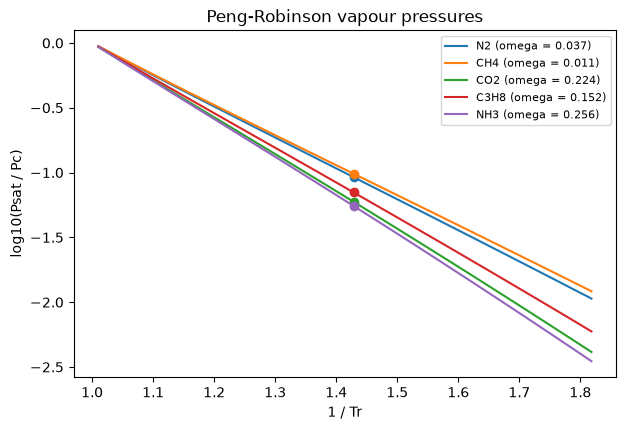

CO2 at 0 °C: PR 3.477 MPa (experiment 3.485 MPa)


In [4]:
plt.figure(figsize=(7, 4.5))
for f in ("N2", "CH4", "CO2", "C3H8", "NH3"):
    sp = rg.get(f); e = rg.PengRobinson(sp)
    Tr = np.linspace(0.55, 0.99, 40)
    ps = [e.saturation_pressure(t * sp.Tc) / sp.Pc for t in Tr]
    line, = plt.plot(1 / Tr, np.log10(ps), label=f"{f} (omega = {sp.omega:.3f})")
    plt.plot(1 / 0.7, -1 - sp.omega, "o", c=line.get_color())
plt.xlabel("1 / Tr"); plt.ylabel("log10(Psat / Pc)"); plt.legend(fontsize=8); plt.title("Peng-Robinson vapour pressures")
plt.show()
print(f"CO2 at 0 °C: PR {pr.saturation_pressure(273.15)/1e6:.3f} MPa (experiment 3.485 MPa)")

## 4. Phase envelope of CO2

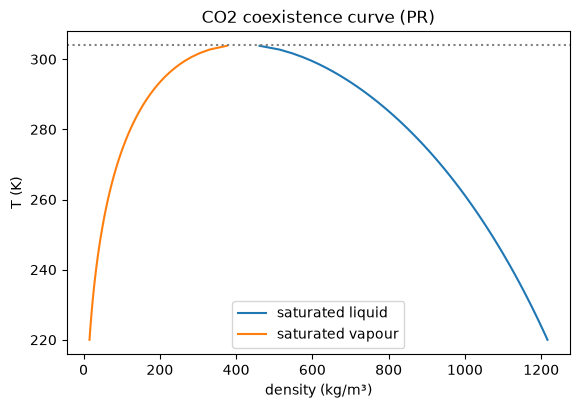

In [5]:
T = np.linspace(220, co2.Tc - 0.3, 80)
rl, rv = [], []
for t in T:
    ps = pr.saturation_pressure(t)
    rl.append(pr.density(t, ps, "liquid")); rv.append(pr.density(t, ps, "vapor"))
plt.figure(figsize=(6.5, 4.2))
plt.plot(rl, T, label="saturated liquid"); plt.plot(rv, T, label="saturated vapour")
plt.axhline(co2.Tc, ls=":", c="gray"); plt.xlabel("density (kg/m³)"); plt.ylabel("T (K)"); plt.legend()
plt.title("CO2 coexistence curve (PR)"); plt.show()

## 5. Residual enthalpy of nitrogen

$H - H^{ig}$ measures how far the real gas departs from ideal behaviour. It sets the size of the Joule-Thomson cooling in a throttling valve.

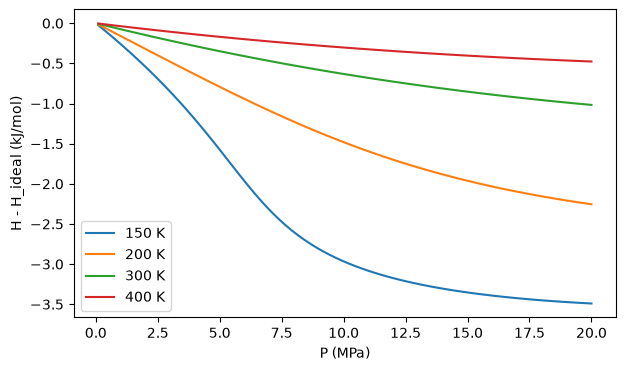

In [6]:
n2 = rg.PengRobinson(rg.get("N2"))
P = np.linspace(1e5, 2e7, 80)
plt.figure(figsize=(7, 4))
for T in (150.0, 200.0, 300.0, 400.0):
    plt.plot(P / 1e6, [n2.enthalpy_departure(T, p) / 1000 for p in P], label=f"{T:.0f} K")
plt.xlabel("P (MPa)"); plt.ylabel("H - H_ideal (kJ/mol)"); plt.legend(); plt.show()